# 👖 Autoencoders on Fashion MNIST

In this notebook, we'll walk through the steps required to train your own autoencoder on the fashion MNIST dataset.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, datasets, callbacks
import tensorflow.keras.backend as K

from notebooks.utils import display

## 0. Parameters <a name="parameters"></a>

In [2]:
IMAGE_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 100
BUFFER_SIZE = 1000
VALIDATION_SPLIT = 0.2
EMBEDDING_DIM = 2
EPOCHS = 3

## 1. Prepare the data <a name="prepare"></a>

In [3]:
# Load the data
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

In [4]:
# Preprocess the data


def preprocess(imgs):
    """
    Normalize and reshape the images
    """
    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

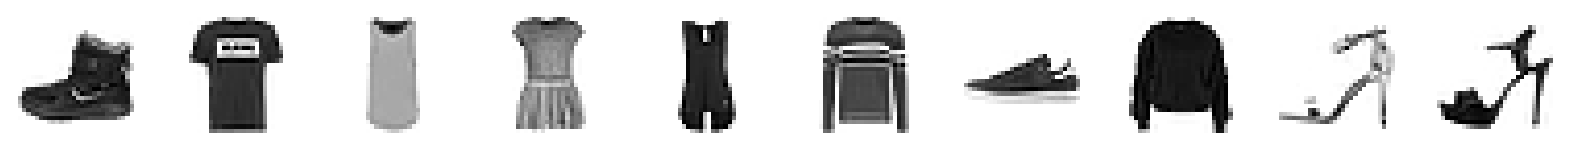

In [5]:
# Show some items of clothing from the training set
display(x_train)

## 2. Build the autoencoder <a name="build"></a>

In [6]:
# Encoder
encoder_input = layers.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS), name="encoder_input"
)
x = layers.Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(
    encoder_input
)
x = layers.Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape_before_flattening = K.int_shape(x)[1:]  # the decoder will need this!

x = layers.Flatten()(x)
encoder_output = layers.Dense(EMBEDDING_DIM, name="encoder_output")(x)

encoder = models.Model(encoder_input, encoder_output)
encoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 96,770 (378.01 KB)

 Trainable params: 96,770 (378.01 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Decoder
decoder_input = layers.Input(shape=(EMBEDDING_DIM,), name="decoder_input")
x = layers.Dense(np.prod(shape_before_flattening))(decoder_input)
x = layers.Reshape(shape_before_flattening)(x)
x = layers.Conv2DTranspose(
    128, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    64, (3, 3), strides=2, activation="relu", padding="same"
)(x)
x = layers.Conv2DTranspose(
    32, (3, 3), strides=2, activation="relu", padding="same"
)(x)
decoder_output = layers.Conv2D(
    CHANNELS,
    (3, 3),
    strides=1,
    activation="sigmoid",
    padding="same",
    name="decoder_output",
)(x)

decoder = models.Model(decoder_input, decoder_output)
decoder.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2048)           │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_output (Conv2D)         │ (None, 32, 32, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 246,273 (962.00 KB)

 Trainable params: 246,273 (962.00 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Autoencoder
autoencoder = models.Model(
    encoder_input, decoder(encoder_output)
)  # decoder(encoder_output)
autoencoder.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 16, 16, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_output (Dense)          │ (None, 2)              │         4,098 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_1 (Functional)       │ (None, 32, 32, 1)      │       246,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 343,043 (1.31 MB)

 Trainable params: 343,043 (1.31 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Train the autoencoder <a name="train"></a>

In [9]:
# Compile the autoencoder
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

In [10]:
# Create a model save checkpoint
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint/checkpoint.keras",
    save_weights_only=False,
    save_freq="epoch",
    monitor="loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")

In [11]:
autoencoder.fit(
    x_train,
    x_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test, x_test),
    callbacks=[model_checkpoint_callback, tensorboard_callback],
    verbose=2,
)

Epoch 1/3


600/600 - 10s - 16ms/step - loss: 0.2894 - val_loss: 0.2615


Epoch 2/3


600/600 - 9s - 16ms/step - loss: 0.2574 - val_loss: 0.2578


Epoch 3/3


600/600 - 10s - 16ms/step - loss: 0.2544 - val_loss: 0.2549


In [12]:
# Save the final models
autoencoder.save("./models/autoencoder.keras")
encoder.save("./models/encoder.keras")
decoder.save("./models/decoder.keras")

## 4. Reconstruct using the autoencoder <a name="reconstruct"></a>

In [13]:
n_to_predict = 5000
example_images = x_test[:n_to_predict]
example_labels = y_test[:n_to_predict]

  1/157 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step

 21/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

 41/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 61/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

 81/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

...

121/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

141/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


Example real clothing items


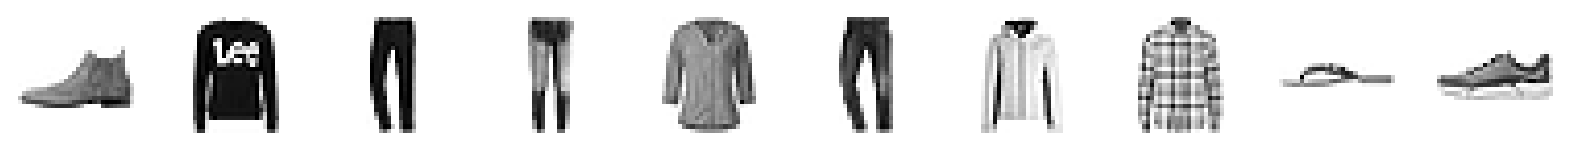

Reconstructions


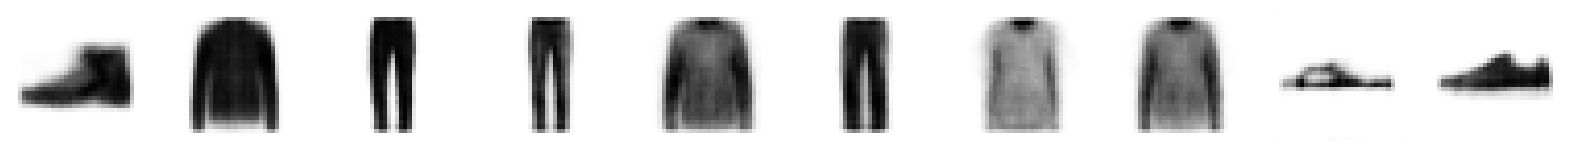

In [14]:
predictions = autoencoder.predict(example_images)

print("Example real clothing items")
display(example_images)
print("Reconstructions")
display(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


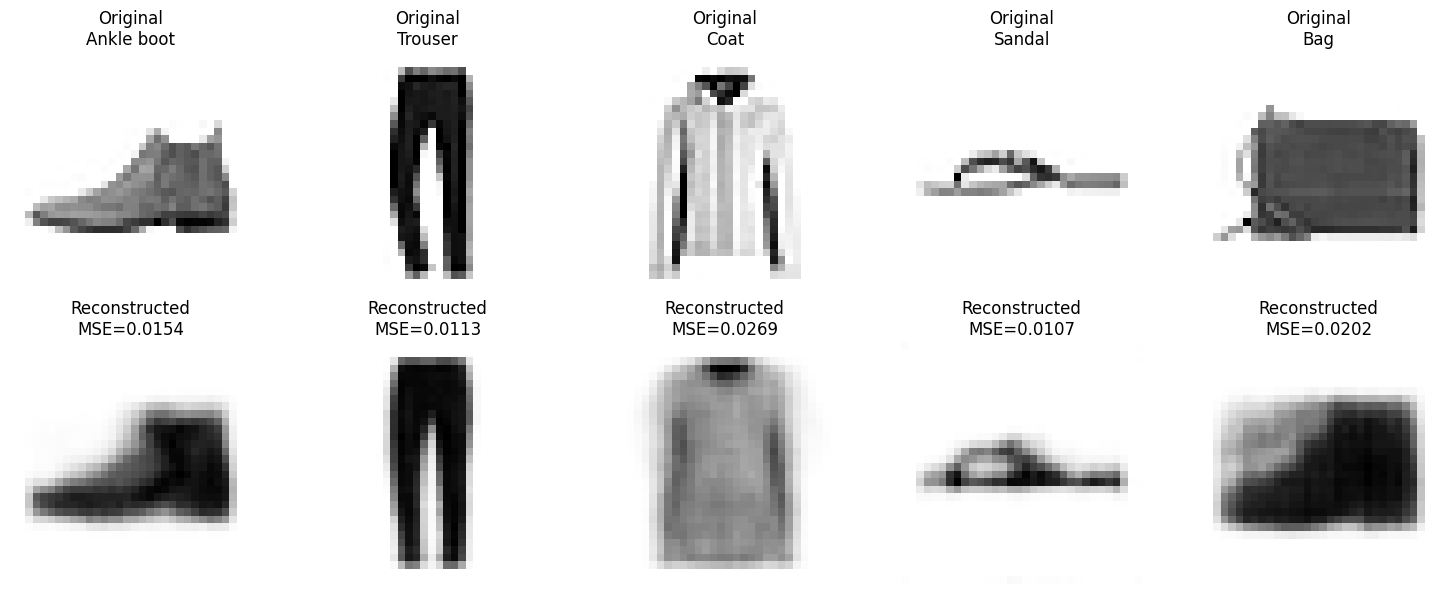

Image 0 (Ankle boot): MSE = 0.01537
Image 2 (Trouser): MSE = 0.01127
Image 6 (Coat): MSE = 0.02693
Image 8 (Sandal): MSE = 0.01065
Image 18 (Bag): MSE = 0.02023


In [15]:
# 5. Compare 5 chosen images: original vs. reconstruction

# Pick 5 images of my own choice (different clothing categories) from the test set
chosen_idx = [0, 2, 6, 8, 18]  # Ankle boot, Trouser, Coat, Sandal, Bag

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

chosen_images = x_test[chosen_idx]
chosen_labels = y_test[chosen_idx]
chosen_recons = autoencoder.predict(chosen_images)

# Per-image reconstruction error (mean squared error)
mse_per_image = np.mean((chosen_images - chosen_recons) ** 2, axis=(1, 2, 3))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, idx in enumerate(chosen_idx):
    axes[0, i].imshow(chosen_images[i, :, :, 0], cmap="gray_r")
    axes[0, i].set_title(f"Original\n{class_names[chosen_labels[i]]}")
    axes[0, i].axis("off")

    axes[1, i].imshow(chosen_recons[i, :, :, 0], cmap="gray_r")
    axes[1, i].set_title(f"Reconstructed\nMSE={mse_per_image[i]:.4f}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.savefig("./output/five_image_comparison.png", dpi=150)
plt.show()

for i, idx in enumerate(chosen_idx):
    print(f"Image {idx} ({class_names[chosen_labels[i]]}): MSE = {mse_per_image[i]:.5f}")


### 6. Discrepancies between original and reconstructed images

I picked five images that cover very different clothing shapes: an ankle boot, a pair of
trousers, a coat, a sandal, and a bag. Because the encoder compresses each 32x32 image down
to just two numbers (`EMBEDDING_DIM = 2`), the decoder only has a tiny amount of information
to work with when it rebuilds the image, so some loss of detail is expected everywhere. Looking
at the actual outputs:

- **Sandal (MSE = 0.0107)** and **trousers (MSE = 0.0113)** reconstructed the best out of the
  five. Both have simple, blocky silhouettes with large uniform regions, so the decoder was
  able to reproduce their outline almost cleanly, even though the edges came out slightly
  softened compared to the sharp original.
- **Ankle boot (MSE = 0.0154)** kept its overall shoe shape and sole, but the reconstruction
  smudges the finer structure, like the ankle collar and the boundary between the sole and
  upper, into a single blurry mass. The item is still clearly recognizable as footwear, though.
- **Bag (MSE = 0.0202)** kept its rectangular body, but the reconstruction lost most of the
  thin shoulder strap and the fine seam/clasp lines visible in the original, turning the bag
  into a mostly solid dark block.
- **Coat (MSE = 0.0269)**, which had the highest error of the five, showed the most noticeable
  discrepancy. The original has a light body with visible dark zipper trim and clearly separated
  sleeves, but the reconstruction blurs all of that into a plain grey pullover-like shape,
  losing the trim contrast and even part of one sleeve boundary.

The general pattern is that items with a simple, uniform silhouette (sandal, trousers)
reconstruct almost cleanly, while items with fine internal detail or thin structures (straps,
zippers, sharply contrasting trim) lose that detail and get "averaged out" into a smoother,
blobbier version of the original. This makes sense given the extremely small 2D latent
bottleneck: the network can only preserve the coarsest, most dominant shape information, not
fine texture or edges, which is why every reconstruction looks like a blurred version of the
original rather than a sharp copy.
